-*- encoding: utf-8 -*-
This file is part of GaPSE
Copyright (C) 2022 Matteo Foglieni
GaPSE is free software: you can redistribute it and/or modify
it under the terms of the GNU General Public License as published by
the Free Software Foundation, either version 3 of the License, or
(at your option) any later version.
GaPSE is distributed in the hope that it will be useful, but
WITHOUT ANY WARRANTY; without even the implied warranty of
MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the GNU
General Public License for more details.
You should have received a copy of the GNU General Public License
along with GaPSE. If not, see <http://www.gnu.org/licenses/>.

# threads_scaling

How much faster GaPSE gets when Julia is given more than one thread, measured rather than
asserted.

The parallel path is a single function, `map_over_ss` in `src/OtherUtils.jl`: the four
`map_ξ_*_multipole` spread their $s$ values over the default thread pool with
`Threads.@threads :dynamic`. Each $s$ is its own quadrature over $\mu$ and the `Cosmology`
is read-only on that path, so the points are independent; the scheduling is `:dynamic`
because the cost of one $s$ grows with $s$ and a static split would leave one thread
running alone on the far end of the grid.

**A notebook cannot change its own thread count.** `JULIA_NUM_THREADS` is read once, when
the kernel process starts, and `Threads.nthreads()` is fixed from then on - there is no
API to resize the pool. So the only way to compare thread counts from here is to start one
Julia process per count. This notebook writes a small worker script into
`threads_scaling/` and runs it with `-t 1`, `-t 2`, ... through `run()`.

(In IJulia the shell escape is `;` at the start of a line, not the `!` of IPython:
`;julia -t 2 worker.jl` would work too. `run()` is used instead because it is plain Julia -
it works in any kernel and in a plain REPL - and because the exit status and the output
come back as values.)

What is timed is `map_ξ_GNC_multipole` for `auto_lensing`, one of the heaviest effects and
one whose per-point cost grows with $s$, at $L = 0$ and with the settings of the unit
tests. The `Cosmology` build and the JIT warm-up happen before the clock starts, so what
is measured is the parallel loop and nothing else.

All the output files are saved in the `threads_scaling/` directory.

In [1]:
"""
    help(x)

Show the docstring of `x`. Useful in VSCode or Jupyter Lab, where prepending `?` doesn't work.
"""
macro help(x)
    quote
        display("text/markdown", @doc $x)
    end
end;
@help @help

```julia
help(x)
```

Show the docstring of `x`. Useful in VSCode or Jupyter Lab, where prepending `?` doesn't work.


## GaPSE setup

In [2]:
using GaPSE
using Plots, LaTeXStrings, DelimitedFiles, Printf
# GR, the default Plots backend: it needs no Python at all, and it is the one that
# works under Julia 1.12 - see the "Which backend" section of ../ipynbs/README.md
gr()

Plots.GRBackend()

In [3]:
const PATH_TO_GAPSE = normpath(joinpath(@__DIR__, ".."));
const DIR = joinpath(@__DIR__, "threads_scaling");
@assert isdir(DIR) "ERROR: DIR=$DIR DOESN'T EXIST!!!"

# the environment the worker processes have to run in: this one
const PROJECT = @__DIR__;
# the julia binary this kernel is running, WITHOUT any thread flag: `Base.julia_cmd()`
# carries `-C`, `-J` and `-g`, but not `--threads`, so `-t` can be appended freely
const JULIA = Base.julia_cmd();

In [4]:
# How many threads this kernel got, and how many the machine has. The scan goes up to
# `Sys.CPU_THREADS`: asking for more than that oversubscribes - Julia does not clamp,
# it really starts the threads - and only measures the scheduler.
@printf("Threads.nthreads() of this kernel : %d\n", Threads.nthreads())
@printf("Sys.CPU_THREADS                   : %d\n", Sys.CPU_THREADS)

const THREAD_COUNTS = collect(1:Sys.CPU_THREADS);
# the sizes of the `s` grid handed to `map_over_ss`. 3 is not an arbitrary small number:
# it is what every `*_specific_ss.txt` of the test suite contains, i.e. what the unit
# tests actually give the parallel loop
const N_SS = [3, 16, 64, 256];
const N_REP = 5;
const EFFECT = "auto_lensing";

Threads.nthreads() of this kernel : 1
Sys.CPU_THREADS                   : 8


## The worker script

One process per thread count. The script is written here, so that this notebook stays the
only source: editing the cell below and re-running it replaces `threads_scaling/worker.jl`.

In [6]:
@help grid

```julia
grid(args...; kw...)
```

Create a grid layout for subplots. `args` specify the dimensions, e.g. `grid(3,2, widths = (0.6,0.4))` creates a grid with three rows and two columns of different width.


In [7]:
const WORKER_SRC = raw"""
# Written by theory/threads_scaling.ipynb - do not edit by hand.
#
# One process of the scaling study: it builds the Cosmology, warms the JIT up, and only
# then times `map_ξ_GNC_multipole`, i.e. the function that `map_over_ss` parallelises.
#
# usage:  julia -t <N> --project=<theory> worker.jl <outdir> <n_ss...>

using GaPSE, Printf

const OUTDIR = abspath(ARGS[1])
const N_SS = parse.(Int, ARGS[2:end])
const NT = Threads.nthreads()
const N_REP = 5
const EFFECT = "auto_lensing"
const PATH_TO_GAPSE = normpath(joinpath(@__DIR__, "..", ".."))

params = GaPSE.CosmoParams(0.05, 0.20, pi / 2.0;
    Ω_b = 0.0489, Ω_cdm = 0.251020, 
    h_0 = 0.70, s_lim = 1e-2, z_spline_lim = 1000.0,
    b1 = 1.0, s_b1 = 0.0, 𝑓_evo1 = 0.0, 
    b2 = nothing, s_b2 = nothing, 𝑓_evo2 = nothing,
    IPS_opts = Dict(
        :fit_left_min => 1e-6, :fit_left_max => 3e-6,
        :fit_right_min => 1e1, :fit_right_max => 2e1),
    IPSTools_opts = Dict(
        :N => 1024, :fit_min => 0.05, :fit_max => 0.5, 
        :con => true, :k_min => 1e-8, :k_max => 10.0),
);

COSMO = GaPSE.Cosmology(
    params,
    joinpath(PATH_TO_GAPSE, "data", "WideA_ZA_background.dat"),
    joinpath(PATH_TO_GAPSE, "data", "WideA_ZA_pk.dat"),
    joinpath(PATH_TO_GAPSE, "data", "F_REFERENCE_pi2.txt"),
    joinpath(PATH_TO_GAPSE, "data", "IntegrF_REFERENCE_pi2_z005020.txt")
);

const KW = GaPSE.specif_kwargs_GNC(
    EFFECT, 
    Dict(
        :use_windows => false, :enhancer => 1e8, 
        :obs => :noobsvel,
        :N_trap => 30, :N_lob => 30, :N_χs => 40, :N_χs_2 => 20,
        :suit_sampling => false, :alg => :lobatto
    )
);

run_map(v_ss) = GaPSE.map_ξ_GNC_multipole(COSMO, EFFECT, v_ss; L=0, pr=true, KW...)[2]

grid(n) = 10 .^ range(0, log10(2 * COSMO.s_max), length=n)

run_map(grid(4))   # warm-up: everything below is measured on compiled code

open(joinpath(OUTDIR, "times.txt"), "a") do io
    for n in N_SS
        v_ss = grid(n)
        xis = run_map(v_ss)
        t = minimum([(s = time(); run_map(v_ss); time() - s) for _ in 1:N_REP])
        @printf(io, "%3d %5d %14.6f\n", NT, n, t)
        flush(io)
        # the largest grid is also written out in full, to check that the thread count
        # changes nothing but the wall time
        if n == maximum(N_SS)
            open(joinpath(OUTDIR, "xis_$(NT)threads.txt"), "w") do f
                for x in xis
                    @printf(f, "%.17g\n", x)
                end
            end
        end
    end
end
println("worker done: nthreads = ", NT)
""";

const WORKER = joinpath(DIR, "worker.jl");
write(WORKER, WORKER_SRC);
println("written $(WORKER)  ($(length(split(WORKER_SRC, '\n'))) lines)")

written /Users/di75tom/AAA_TESI_MAGISTRALE/GaPSE_CODING/GaPSE-worktree/threads/theory/threads_scaling/worker.jl  (73 lines)


## Running the scan, and reading it back

In [8]:
"""
    run_scan(; thread_counts=THREAD_COUNTS, n_ss=N_SS)

Run one worker process per entry of `thread_counts`, appending to
`threads_scaling/times.txt`. The old results are deleted first, so the file always holds
exactly one scan.

Each process pays for its own `Cosmology` build and JIT warm-up - about a minute - before
it times anything, so the whole scan takes a few minutes.
"""
function run_scan(; thread_counts=THREAD_COUNTS, n_ss=N_SS)
    rm(joinpath(DIR, "times.txt"), force=true)
    foreach(f -> rm(joinpath(DIR, f), force=true),
        filter(f -> startswith(f, "xis_") && endswith(f, "threads.txt"), readdir(DIR)))
    for t in thread_counts
        cmd = `$JULIA -t $t --project=$PROJECT $WORKER $DIR $n_ss`
        @printf("-t %-3d ... ", t)
        el = @elapsed run(pipeline(cmd, stdout=devnull))
        @printf("done in %6.1f s (build + JIT + %d timed runs)\n", el, length(n_ss) * N_REP)
    end
    nothing
end;

In [9]:
"""
    read_times() :: Matrix{Float64}

The scan as a matrix with one row per `(threads, n_ss)` pair: threads, n_ss, seconds.
"""
read_times() = readdlm(joinpath(DIR, "times.txt"));

"""
    times_of(tab, n) :: Vector{Float64}

The wall times of the grid of `n` points, ordered as `THREAD_COUNTS`.
"""
times_of(tab, n) = [tab[findfirst(i -> tab[i, 1] == t && tab[i, 2] == n, axes(tab, 1)), 3]
                    for t in THREAD_COUNTS];

In [10]:
"""
    table_times(io=stdout)

Wall time, speedup against one thread, and parallel efficiency, for every grid size.
"""
function table_times(io=stdout)
    tab = read_times()
    for n in N_SS
        ts = times_of(tab, n)
        @printf(io, "\n%d points on the s grid\n", n)
        @printf(io, "  %8s %12s %10s %12s\n", "threads", "time [s]", "speedup", "efficiency")
        for (k, t) in enumerate(THREAD_COUNTS)
            @printf(io, "  %8d %12.4f %10.2fx %11.0f%%\n",
                t, ts[k], ts[1] / ts[k], 100 * (ts[1] / ts[k]) / t)
        end
    end
end;

In [11]:
"""
    check_identical(io=stdout)

Compare, digit by digit, the `ξ` of the largest grid as every thread count produced it.
`map_over_ss` writes each result into its own slot of a pre-allocated vector and the
`Cosmology` is only read, so the answer must not depend on how the points were split.
"""
function check_identical(io=stdout)
    files = sort(filter(f -> startswith(f, "xis_") && endswith(f, "threads.txt"), readdir(DIR)))
    vals = Dict(f => readdlm(joinpath(DIR, f))[:, 1] for f in files)
    ref = first(files)
    @printf(io, "%-24s %8s %28s\n", "file", "n", "max |x - x_ref| / |x_ref|")
    for f in files
        d = maximum(abs.((vals[f] .- vals[ref]) ./ vals[ref]))
        @printf(io, "%-24s %8d %28s\n", f, length(vals[f]),
            d == 0 ? "0  (bit for bit)" : @sprintf("%.3e", d))
    end
    nothing
end;

## Plot functions

In [61]:
function plot_kwargs(kwargs...)
    dict_defaults = Dict(
        :size => (1000, 400), :dpi => 300, :legendposition => :outerright,
        :legendfontsize => 11, :guidefontsize => 14, :tickfontsize => 11,
        :titlefontsize => 16, :left_margin => 10Plots.mm,
    )
    # In "merge", if a key is repeated in the input dicts, the LAST collection value has priority
    merge(dict_defaults, Dict(kwargs))
end;
func_linecolor(i::Int) = i>0 ? [:green, :orange, :blue, :red, :cyan, :grey, :black][(i-1)%7+1] : throw(AssertionError("only positive integers allowed"));
func_markershape(i::Int) = i>0 ? [:circle, :dtriangle, :diamond, :rect][(i-1)%4+1] : throw(AssertionError("only positive integers allowed"));

In [23]:
logticks(lo, hi; step=1) = 10.0 .^ (floor(Int, log10(lo)):step:ceil(Int, log10(hi)))

logticks (generic function with 1 method)

In [24]:
function save_plot(p, name)
    savefig(p, joinpath(DIR, name))
    nothing
end

save_plot (generic function with 1 method)

In [54]:
"""
    plot_times(; kwargs...)

Wall time of `map_ξ_GNC_multipole` against the number of threads, one curve per grid size.
"""
function plot_times(; kwargs...)
    tab = read_times()
    p = plot(; yscale=:log10,
        xlabel="number of threads", ylabel=L"t \; [\mathrm{s}]" * " "^6,
        title="Wall time of " * L"\xi^{\,\mathrm{GNC}}_{\kappa \kappa}" * ", " * L"L=0",
        yguidefontrotation=-90, xticks=THREAD_COUNTS,
        plot_kwargs(:left_margin => 22Plots.mm, :bottom_margin => 8Plots.mm, kwargs...)...)
    for (j,n) in enumerate(N_SS)
        plot!(p, THREAD_COUNTS, times_of(tab, n), 
            lw=2, lc=colors[j], 
            marker=func_markershape(j), ms=4, mc=func_linecolor(j), markerstrokewidth=0,
            label="$n points")
    end
    p
end;

In [71]:
"""
    plot_speedup(; kwargs...)

Speedup and parallel efficiency against the number of threads. The dashed line is the
ideal one; a curve that flattens is a grid too short to keep the threads busy.
"""
function plot_speedup(; kwargs...)
    tab = read_times()
    p1 = plot(; xlabel="number of threads", ylabel=L"\frac{t_1}{t_N}" * " "^1,
        title="Speedup", yguidefontrotation=-90, xticks=THREAD_COUNTS,
        plot_kwargs(:left_margin => 15Plots.mm, :bottom_margin => 8Plots.mm,
            :size => (1000, 340), kwargs...)...)
    plot!(p1, THREAD_COUNTS, THREAD_COUNTS, ls=:dash, lw=2, c=:gray, label="ideal")
    for (j,n) in enumerate(N_SS)
        ts = times_of(tab, n)
        plot!(p1, THREAD_COUNTS, ts[1] ./ ts, 
            lw=2, lc=colors[j], 
            marker=func_markershape(j), ms=4, mc=func_linecolor(j), markerstrokewidth=0,
            label="$n points")
    end
    p2 = plot(; xlabel="number of threads", ylabel=L"\frac{1}{N} \; \frac{t_1}{t_N}" * " "^1,
        title="Parallel efficiency", yguidefontrotation=-90, xticks=THREAD_COUNTS,
        ylims=(0, 1.15),
        plot_kwargs(:left_margin => 15Plots.mm, :bottom_margin => 8Plots.mm,
            :size => (1000, 340), kwargs...)...)
    hline!(p2, [1.0], ls=:dash, lw=2, c=:gray, label="ideal")
    for (j,n) in enumerate(N_SS)
        ts = times_of(tab, n)
        plot!(p2, THREAD_COUNTS, (ts[1] ./ ts) ./ THREAD_COUNTS, 
            lw=2, lc=colors[j], 
            marker=func_markershape(j), ms=4, mc=func_linecolor(j), markerstrokewidth=0,
            label="$n points")
    end
    plot(p1, p2; layout=(2, 1), size=(1000, 700), dpi=300)
end;

## 1. Run the scan

One Julia process per thread count. Most of the time below is the `Cosmology` build and
the JIT of each process, not the measurement.

In [17]:
run_scan()

-t 1   ... 

auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:01
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00


done in   27.1 s (build + JIT + 20 timed runs)
-t 2   ... 

auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00


done in   22.4 s (build + JIT + 20 timed runs)
-t 3   ... 

...

done in   20.4 s (build + JIT + 20 timed runs)
-t 7   ... 

auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00
auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00


done in   20.1 s (build + JIT + 20 timed runs)
-t 8   ... 

auto_lensing, L=0: 100%|████████████████████████████████| Time: 0:00:00


done in   19.8 s (build + JIT + 20 timed runs)


## 2. Wall time, speedup, efficiency

In [18]:
table_times()


3 points on the s grid
   threads     time [s]    speedup   efficiency
         1       0.0080       1.00x         100%
         2       0.0054       1.47x          73%
         3       0.0029       2.79x          93%
         4       0.0028       2.79x          70%
         5       0.0029       2.79x          56%
         6       0.0028       2.84x          47%
         7       0.0028       2.81x          40%
         8       0.0028       2.85x          36%

16 points on the s grid
   threads     time [s]    speedup   efficiency
         1       0.0424       1.00x         100%
         2       0.0218       1.95x          97%
         3       0.0166       2.55x          85%
         4       0.0113       3.76x          94%
         5       0.0111       3.83x          77%
         6       0.0084       5.06x          84%
         7       0.0086       4.96x          71%
         8       0.0057       7.42x          93%

64 points on the s grid
   threads     time [s]    speedup   efficienc

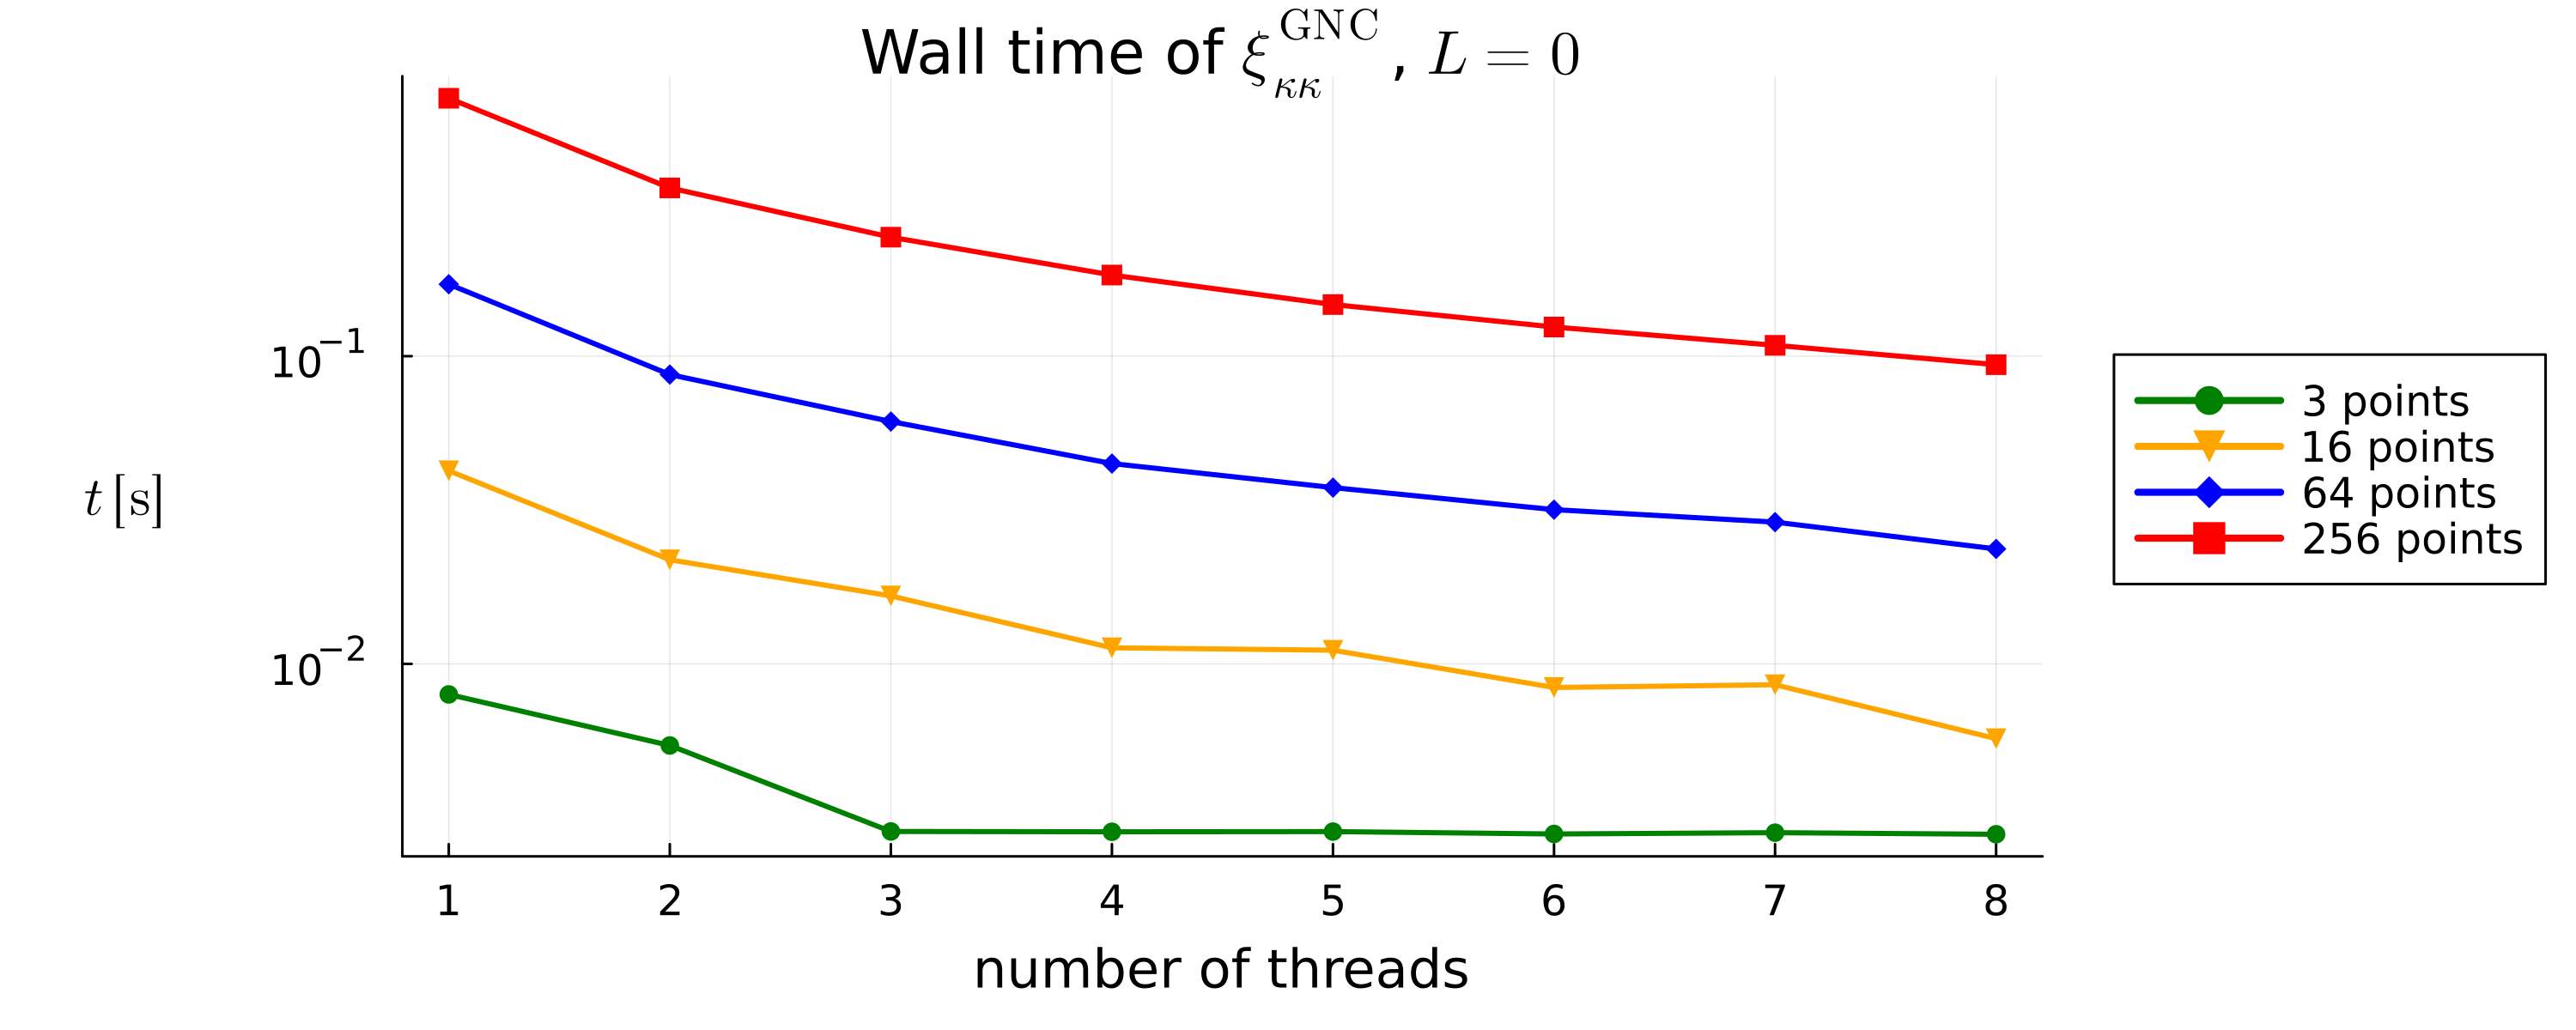

In [67]:
plot_times()

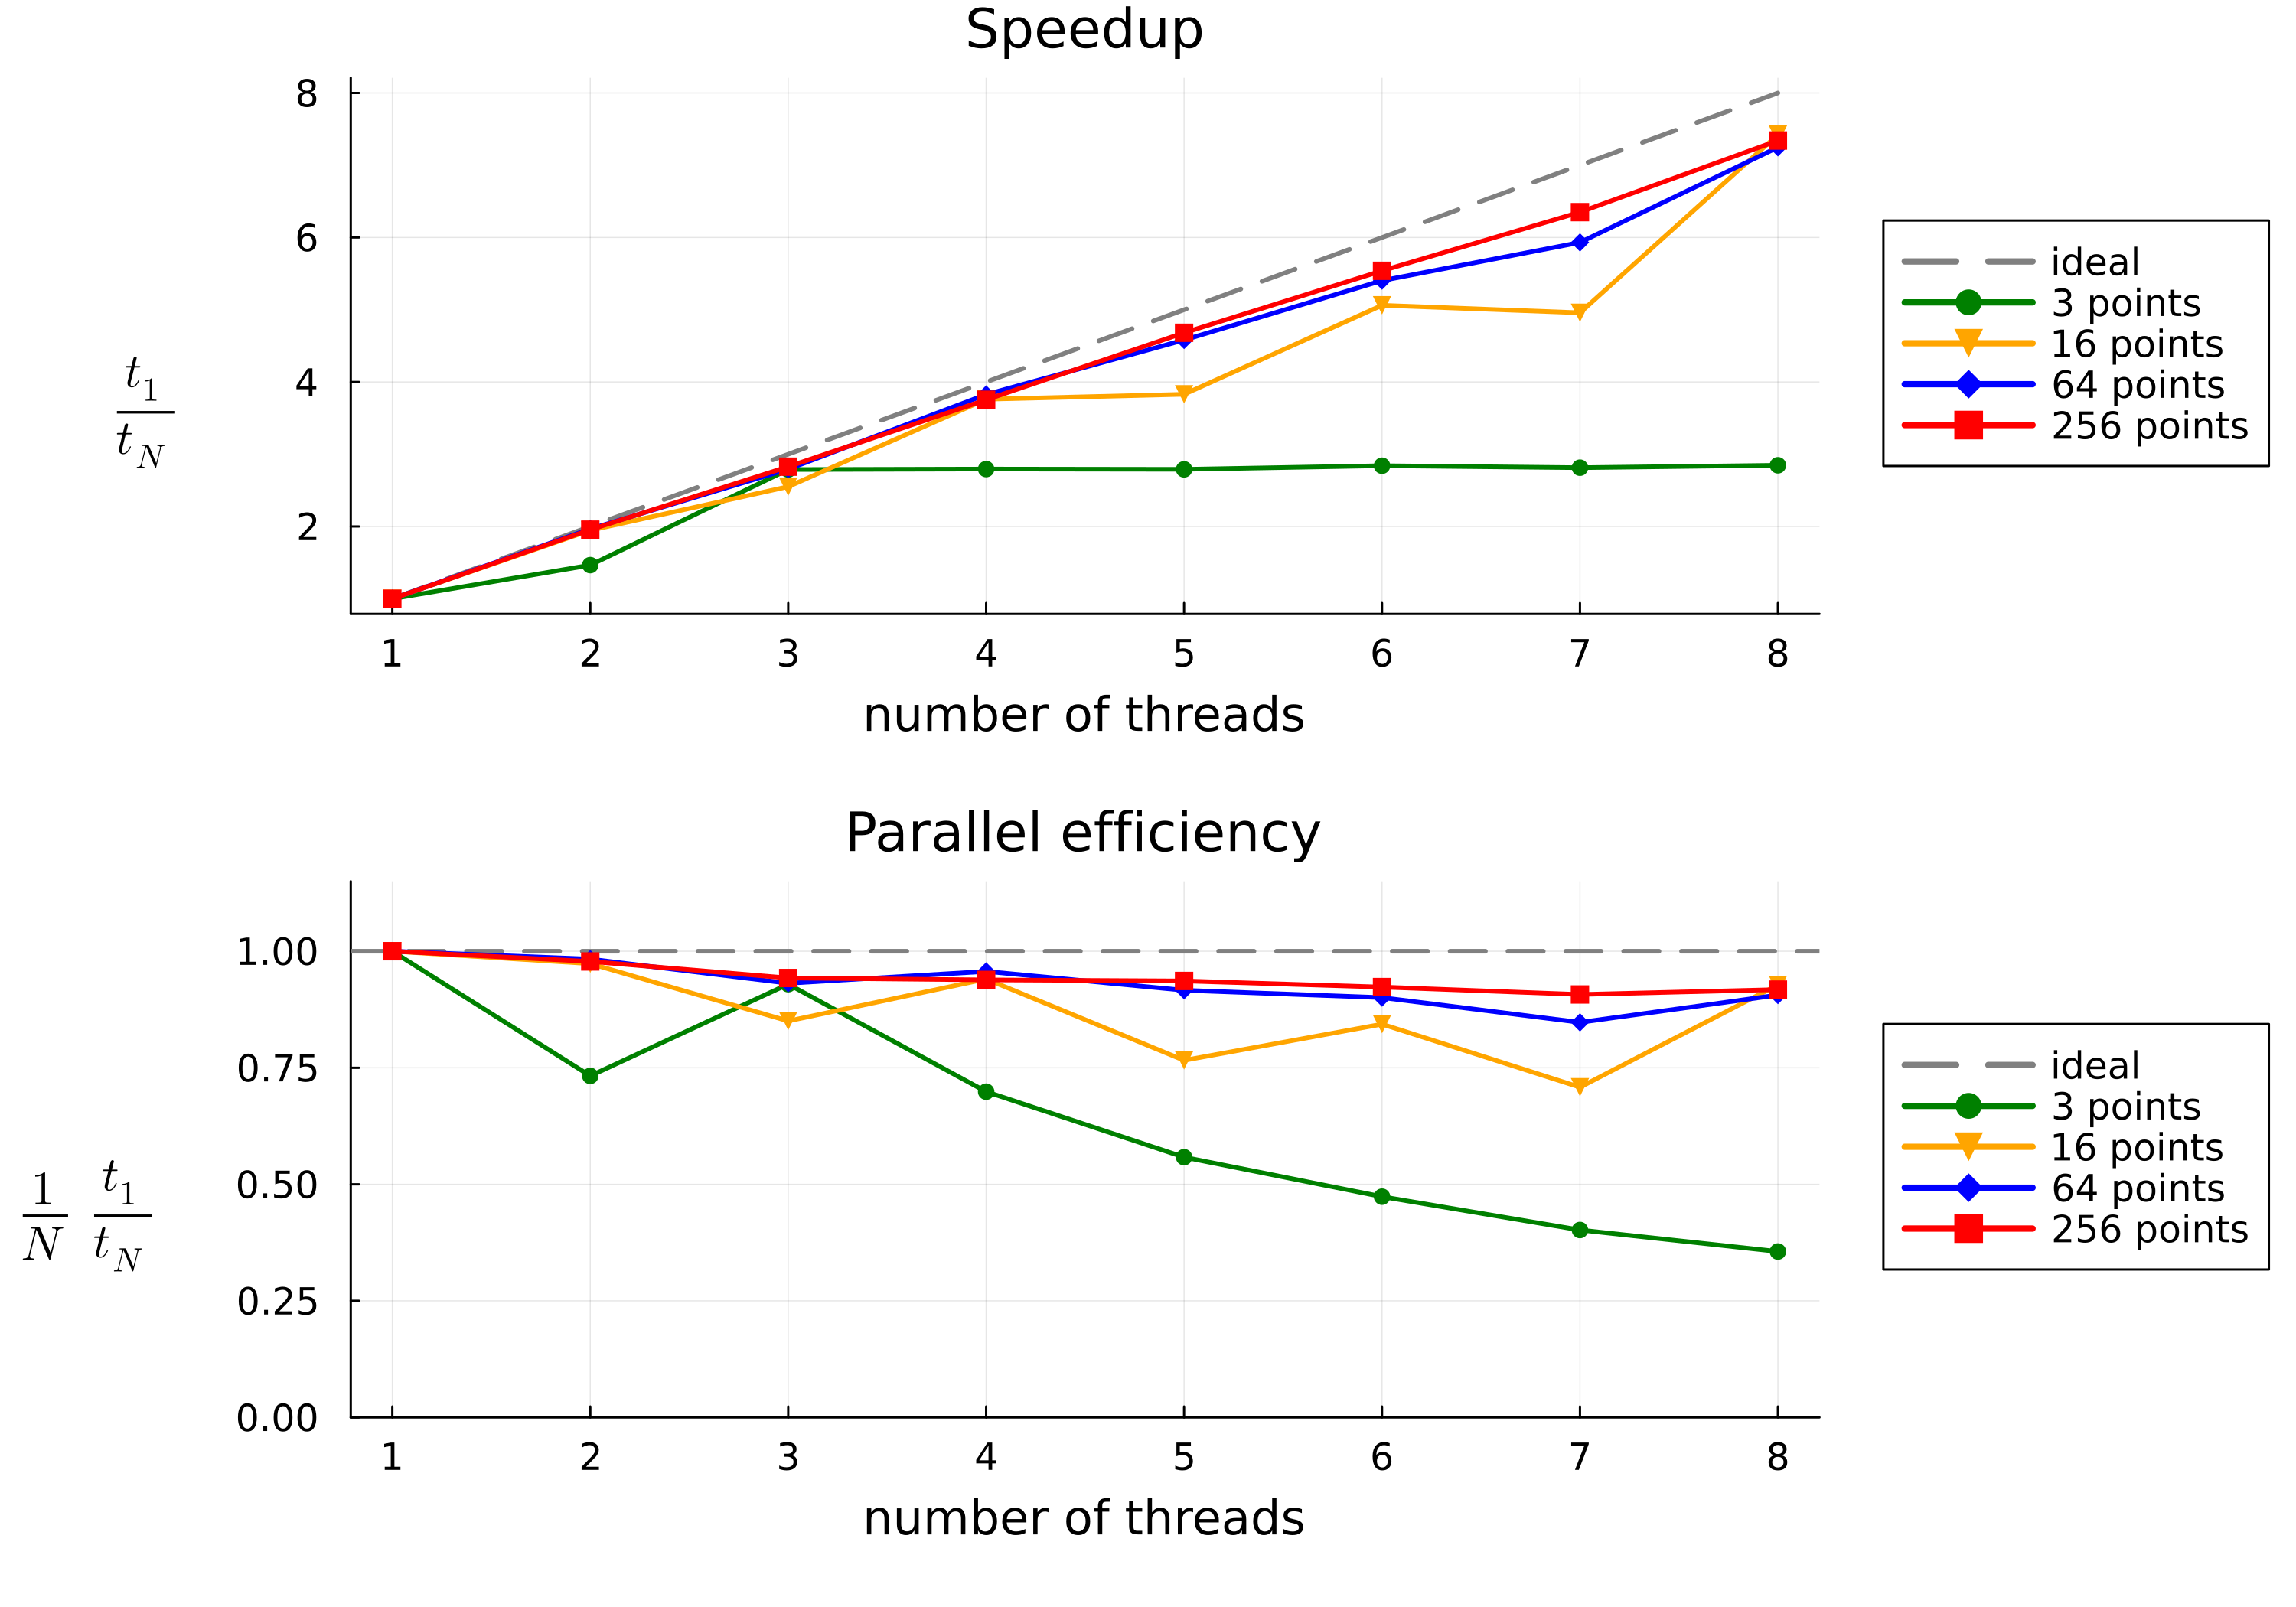

In [72]:
plot_speedup()

The 3-point curve is the one to look at. It tracks the ideal line up to **3** threads -
$3.5\times$ at $N = 3$ - and then stops dead: $3.5\times$ again at $N = 4$. That is
`Threads.@threads` having only three tasks to hand out, so the fourth thread gets nothing
and the wall time becomes the cost of the slowest single point. The larger grids keep
climbing instead, and at 256 points the efficiency is still above 80% on all four threads.

(These are minima over 5 repetitions on a shared 4-vCPU container, so a few percent of
jitter is normal - the 16-point row in particular is not monotonic.)

It is tempting to read the 3-point curve as the explanation of why the 4-thread job of the
CI is not faster than the 1-thread one, since every `*_specific_ss.txt` of the test suite
holds exactly three $s$ values. **It is not the explanation**, and the plot above says so:
three points still buy a factor 3. The real reason is that those testsets barely spend any
time in this loop at all - `test GNC_SumXiMultipoles_P1` is 148 calls of the *scalar*
`sum_ξ_GNC_multipole`, which never reaches `map_over_ss`, plus 48 mapped calls, about 10 s
of arithmetic inside a 230 s testset. The other 220 s are compilation, which is
single-threaded whatever `-t` says. The three points only cap the ceiling of the part that
*can* be parallelised; they are not what makes the job slow.

So the 4-thread CI job earns its place as a *correctness* check, not a speed one - which
is what the next section is about.

## 3. The thread count changes nothing but the time

In [73]:
check_identical()

file                            n    max |x - x_ref| / |x_ref|
xis_1threads.txt              256             0  (bit for bit)
xis_2threads.txt              256             0  (bit for bit)
xis_3threads.txt              256             0  (bit for bit)
xis_4threads.txt              256             0  (bit for bit)
xis_5threads.txt              256             0  (bit for bit)
xis_6threads.txt              256             0  (bit for bit)
xis_7threads.txt              256             0  (bit for bit)
xis_8threads.txt              256             0  (bit for bit)


`map_over_ss` writes `xis[i] = f(v_ss[i])` into a pre-allocated vector, one slot per point,
and everything the closure reads from the `Cosmology` is immutable on this path
(`MySpline` is evaluated with `searchsortedlast`, `GridInterpolations.interpolate` keeps
its scratch in per-call `MVector`s). There is no accumulator and no shared buffer, so the
order in which the points complete cannot change their values - and it does not: the
numbers agree to all 17 digits written out.

## Save the plots and the data

In [74]:
save_plot(plot_times(), "threads_times.png");
save_plot(plot_speedup(), "threads_speedup.png");
open(joinpath(DIR, "threads_scaling_tables.txt"), "w") do io
    @printf(io, "machine: Sys.CPU_THREADS = %d\n", Sys.CPU_THREADS)
    @printf(io, "effect: %s, L = 0, alg = :trap, N_REP = %d\n", EFFECT, N_REP)
    table_times(io)
    println(io)
    check_identical(io)
end
readdir(DIR)

14-element Vector{String}:
 ".ipynb_checkpoints"
 "threads_scaling_tables.txt"
 "threads_speedup.png"
 "threads_times.png"
 "times.txt"
 "worker.jl"
 "xis_1threads.txt"
 "xis_2threads.txt"
 "xis_3threads.txt"
 "xis_4threads.txt"
 "xis_5threads.txt"
 "xis_6threads.txt"
 "xis_7threads.txt"
 "xis_8threads.txt"

## END